## Data Preprocessing
### DSCI 403
#### Clara Pugh and Chandler Bergstrom

This notebook loads in satellite-based sea surface temperature data as well as ARGO float data from NOAA, converts it to a pandas dataframe, and preprocesses it so it's ready to work with. 

In [1]:
# standard imports
import numpy as np
import matplotlib.pyplot as plt

import xarray as xr
import pandas as pd

# import to load ARGO float data
from argopy import DataFetcher as ArgoDataFetcher

from dask.diagnostics import ProgressBar

import os

In [2]:
import time

### Import Sea Surface Temperature (SST) data from NOAA

# Define the OPeNDAP URL for the NOAA OISST dataset
sst_url = "https://coastwatch.pfeg.noaa.gov/erddap/griddap/ncdcOisst21Agg_LonPM180"

# Setup retry parameters
max_attempts = 3
delay_seconds = 10
ds_sst = None

# Open the dataset with xarray using a retry loop
for attempt in range(max_attempts):
    try:
        print(f"Attempt {attempt + 1} to connect to NOAA ERDDAP...")
        ds_sst = xr.open_dataset(sst_url, chunks='auto')
        print("Connection successful!")
        break
    except OSError as e:
        print(f"Connection failed: {e}")
        if attempt < max_attempts - 1:
            print(f"Retrying in {delay_seconds} seconds...")
            time.sleep(delay_seconds)
        else:
            print("All attempts failed. The server is completely offline.")
            raise  # Re-raise the exception to stop execution

# Subset the data to specific region and time of interest, download subset to memory
# This is Gulf Stream region in Jan 2023
if ds_sst is not None:
    subset_sst = ds_sst.sel(time=slice('2023-01-01', '2023-01-31'), latitude=slice(25.0, 45.0), longitude=slice(-80.0, -50.0))

Attempt 1 to connect to NOAA ERDDAP...
Connection successful!


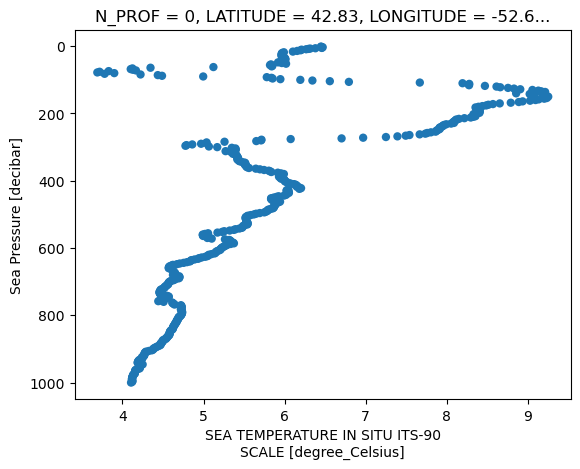

In [3]:
### Import ARGO Float data

# Spatial-temporal bounds format: [lon_min, lon_max, lat_min, lat_max, depth_min, depth_max, date_start, date_end]
argo_fetcher = ArgoDataFetcher().region([-80, -50, 25, 45, 0, 1000, '2023-01-01', '2023-01-31'])

# Fetch the data and convert to an xarray dataset
ds_argo = argo_fetcher.to_xarray()

# Argo data is initially loaded as a 1D list. Convert to standard depth-profile grid for easier analysis
ds_argo_profiles = ds_argo.argo.point2profile()

# Plot a quick temperature-depth profile for the first float
ds_argo_profiles.isel(N_PROF=0).plot.scatter(x="TEMP", y="PRES", yincrease=False, edgecolors='none')

In [4]:
#Matching cell
# Calculate the spatial and temporal bounding box of Argo profiles
min_lon, max_lon = ds_argo_profiles['LONGITUDE'].min().values, ds_argo_profiles['LONGITUDE'].max().values
min_lat, max_lat = ds_argo_profiles['LATITUDE'].min().values, ds_argo_profiles['LATITUDE'].max().values
min_time, max_time = ds_argo_profiles['TIME'].min().values, ds_argo_profiles['TIME'].max().values

# Slice the spatial bounding box, then subsample by taking every 1th pixel
regional_sst = ds_sst.sel(time=slice(min_time, max_time), latitude=slice(min_lat, max_lat), longitude=slice(min_lon, max_lon)).isel(
    latitude=slice(None, None, 1), longitude=slice(None, None, 1))

In [5]:
# download cell
# Download regional block into local memory
from dask.diagnostics import ProgressBar

with ProgressBar():
    regional_sst_loaded = regional_sst.compute()

[########################################] | 100% Completed | 11.95 s


In [7]:
# get SST data from the ARGO locations
colocated_sst = regional_sst_loaded.sst.sel(time=ds_argo_profiles['TIME'], latitude=ds_argo_profiles['LATITUDE'],
                                                     longitude=ds_argo_profiles['LONGITUDE'], method='nearest')

# Add colocated SST back into Argo dataset as a new variable
ds_argo_profiles['matched_sst'] = colocated_sst

# Convert the matched Argo/SST data into a pandas dataframe (GS_0123 means gulf stream january 2023)
df_GS_0123 = ds_argo_profiles.to_dataframe().reset_index()

# convert SST data as well and save it for future visualizations
df_reg_sst = regional_sst_loaded.to_dataframe().reset_index()
df_reg_sst.to_csv('SST_only_gulfstream_jan_2023_not_clean.csv', index=False)

df_GS_0123.head()

,N_PROF,N_LEVELS,zlev,CYCLE_NUMBER,DATA_MODE,DIRECTION,PLATFORM_NUMBER,POSITION_QC,PRES,PRES_ERROR,...,TEMP_ERROR,TEMP_QC,TIME_QC,LATITUDE,LONGITUDE,TIME,time,latitude,longitude,matched_sst
0,0,0,0.0,220,D,A,4903258,1,1.08,2.4,...,0.002,1,1,42.82596,-52.65462,2023-01-01 02:16:37,2023-01-01 12:00:00,42.875,-52.625,9.15
1,0,1,0.0,220,D,A,4903258,1,2.04,2.4,...,0.002,1,1,42.82596,-52.65462,2023-01-01 02:16:37,2023-01-01 12:00:00,42.875,-52.625,9.15
2,0,2,0.0,220,D,A,4903258,1,2.96,2.4,...,0.002,1,1,42.82596,-52.65462,2023-01-01 02:16:37,2023-01-01 12:00:00,42.875,-52.625,9.15
3,0,3,0.0,220,D,A,4903258,1,3.96,2.4,...,0.002,1,1,42.82596,-52.65462,2023-01-01 02:16:37,2023-01-01 12:00:00,42.875,-52.625,9.15
4,0,4,0.0,220,D,A,4903258,1,5.04,2.4,...,0.002,1,1,42.82596,-52.65462,2023-01-01 02:16:37,2023-01-01 12:00:00,42.875,-52.625,9.15


In [40]:
print(df_GS_0123.info())
print(df_GS_0123.describe())

<class 'pandas.DataFrame'>
RangeIndex: 150070 entries, 0 to 150069
Data columns (total 25 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   N_PROF           150070 non-null  int64         
 1   N_LEVELS         150070 non-null  int64         
 2   zlev             150070 non-null  float32       
 3   CYCLE_NUMBER     150070 non-null  int64         
 4   DATA_MODE        150070 non-null  str           
 5   DIRECTION        150070 non-null  str           
 6   PLATFORM_NUMBER  150070 non-null  int64         
 7   POSITION_QC      150070 non-null  int64         
 8   PRES             97145 non-null   float32       
 9   PRES_ERROR       113774 non-null  float32       
 10  PRES_QC          150070 non-null  int64         
 11  PSAL             97145 non-null   float32       
 12  PSAL_ERROR       70420 non-null   float32       
 13  PSAL_QC          150070 non-null  int64         
 14  TEMP             97145 non-null

- There a null values that we will have to deal with in the columns: PRES, PRES_ERROR, PSAL, PSAL_ERROR, TEMP, TEMP_ERROR
- There are a few non-numeric columns: DATA_MODE and DIRECTION are strings, and TIME and tim are in datetime64
- zlev is zero for all rows because this column comes from the SST dataset, whcih only has surface data. I will remove this column because it does not give us any real data

In [67]:
df_GS_0123 = df_GS_0123.drop(columns=['zlev'])

### Chandler input below

I made a copy of Clara's work and am continuing it below!

In [68]:
# calcs the euclidean distance

df = df_GS_0123.reset_index()
df["match_dist_deg"] = np.hypot(df["LATITUDE"] - df["latitude"],
                                df["LONGITUDE"] - df["longitude"])
print(df["match_dist_deg"].describe())

count    150070.000000
mean          0.942525
std           0.354386
min           0.162022
25%           0.670449
50%           0.942359
75%           1.190966
max           2.003140
Name: match_dist_deg, dtype: float64


In [69]:
print(df["TEMP_QC"].value_counts())
print(df["DATA_MODE"].value_counts())

TEMP_QC
1    150070
Name: count, dtype: int64
DATA_MODE
D    113774
R     30014
A      6282
Name: count, dtype: int64


In [70]:
# filtering bad data, calc temp outliers, printing stats

n0 = len(df)
df = df[df["TEMP_QC"].isin([1, 2]) & df["PRES_QC"].isin([1, 2])]
df = df.dropna(subset=["TEMP", "PRES"])
print(n0, "->", len(df), "rows")
df = df.drop(columns=["time", "latitude", "longitude"])  # redundant after match distance
df["TEMP_MINUS_SST"] = df["TEMP"] - df["matched_sst"]
surface = df[df["PRES"] <= 10]
print(surface["TEMP_MINUS_SST"].describe())

150070 -> 97145 rows
count    1741.000000
mean       -0.105634
std         2.114493
min       -14.555000
25%        -0.403000
50%         0.087999
75%         0.467999
max         9.429001
Name: TEMP_MINUS_SST, dtype: float64


### Match distance in km, cleans the data, and compares by mode

In [80]:
# calc distances and filtering more data

df = df_GS_0123.reset_index()
dy = (df["LATITUDE"] - df["latitude"]) * 111
dx = (df["LONGITUDE"] - df["longitude"]) * 111 * np.cos(np.radians(df["LATITUDE"]))
df["match_dist_km"] = np.hypot(dx, dy)
df = df.dropna(subset=["TEMP", "PRES"])
df["TEMP_MINUS_SST"] = df["TEMP"] - df["matched_sst"]



In [81]:
surface = df[df["PRES"] <= 10]
print(len(df), len(surface))
print(surface[["match_dist_km", "TEMP_MINUS_SST"]].describe())
print(surface.groupby("DATA_MODE")["TEMP_MINUS_SST"].describe())

97145 1741
       match_dist_km  TEMP_MINUS_SST
count    1741.000000     1741.000000
mean       93.576736       -0.105634
std        35.448538        2.114493
min        16.473793      -14.555000
25%        67.324938       -0.403000
50%        92.139929        0.087999
75%       117.713461        0.467999
max       189.036226        9.429001
            count      mean       std        min       25%     50%      75%  \
DATA_MODE                                                                     
A            31.0 -0.793968  1.930930  -6.295000 -0.344501 -0.0900  0.15600   
D          1262.0 -0.173695  2.109811 -14.555000 -0.524750  0.0270  0.43775   
R           448.0  0.133723  2.119756  -5.714999 -0.142250  0.1825  1.02400   

                max  
DATA_MODE            
A          0.365999  
D          9.429001  
R          5.002000  


### Meaning:

What the numbers say

Median difference is about 0.09 °C, and the middle 50% of rows are between about -0.4 and +0.5 °C. 
Tails are extreme- the std (2.1 °C) is a lot bigger than middle sections spread, and the range is -14.6 to 9.4 °C. 
* A 14 °C gap between two measurements of the same ocean surface isn’t a measurement difference. It’s either a mismatch (the satellite pixel was up to 190 km away, possibly across the Gulf Stream front, where there are sharp temperature cliffs) or a bad value.

  
D, R and A all are similar (~2 °C). 
Only 1,741 of the 97,145 valid rows are near-surface (≤ 10 dbar, about 8 per profile).

In [72]:
surface = surface.copy()
surface["ABS_DIFF"] = surface["TEMP_MINUS_SST"].abs()

# does the error grow with match distance?
surface["dist_bin"] = pd.cut(surface["match_dist_km"], [0, 50, 100, 150, 200])
print(surface.groupby("dist_bin", observed=True)["ABS_DIFF"].agg(["count", "median", "std"]))

# look at the worst cases
cols = ["PLATFORM_NUMBER", "CYCLE_NUMBER", "TIME", "LATITUDE", "LONGITUDE",
        "PRES", "TEMP", "matched_sst", "match_dist_km", "TEMP_MINUS_SST"]
print(surface.sort_values("ABS_DIFF", ascending=False)[cols].head(15))

            count    median       std
dist_bin                             
(0, 50]       178  0.307500  1.478871
(50, 100]     861  0.401000  1.437501
(100, 150]    599  0.605000  2.331022
(150, 200]    103  0.651999  0.864967
        PLATFORM_NUMBER  CYCLE_NUMBER                TIME  LATITUDE  \
86552           6990501            15 2023-01-19 11:15:21  41.35100   
86553           6990501            15 2023-01-19 11:15:21  41.35100   
126338          4903280            84 2023-01-27 14:57:01  41.08326   
126343          4903280            84 2023-01-27 14:57:01  41.08326   
126347          4903280            84 2023-01-27 14:57:01  41.08326   
126340          4903280            84 2023-01-27 14:57:01  41.08326   
126348          4903280            84 2023-01-27 14:57:01  41.08326   
126339          4903280            84 2023-01-27 14:57:01  41.08326   
126342          4903280            84 2023-01-27 14:57:01  41.08326   
126344          4903280            84 2023-01-27 14:57:01  41.

In [73]:
# w/ out pandas 
surface = surface.copy()
surface["ABS_DIFF"] = surface["TEMP_MINUS_SST"].abs()

edges = [0, 50, 100, 150, 200]
bins = np.digitize(surface["match_dist_km"], edges)
for b in range(1, len(edges)):
    sel = surface.loc[bins == b, "ABS_DIFF"]
    print(f"{edges[b-1]}-{edges[b]} km: n={len(sel)}, median={sel.median():.2f}, std={sel.std():.2f}")

cols = ["PLATFORM_NUMBER", "CYCLE_NUMBER", "TIME", "LATITUDE", "LONGITUDE",
        "PRES", "TEMP", "matched_sst", "match_dist_km", "TEMP_MINUS_SST"]
print(surface.sort_values("ABS_DIFF", ascending=False)[cols].head(15))

0-50 km: n=178, median=0.31, std=1.48
50-100 km: n=861, median=0.40, std=1.44
100-150 km: n=599, median=0.60, std=2.33
150-200 km: n=103, median=0.65, std=0.86
        PLATFORM_NUMBER  CYCLE_NUMBER                TIME  LATITUDE  \
86552           6990501            15 2023-01-19 11:15:21  41.35100   
86553           6990501            15 2023-01-19 11:15:21  41.35100   
126338          4903280            84 2023-01-27 14:57:01  41.08326   
126343          4903280            84 2023-01-27 14:57:01  41.08326   
126347          4903280            84 2023-01-27 14:57:01  41.08326   
126340          4903280            84 2023-01-27 14:57:01  41.08326   
126348          4903280            84 2023-01-27 14:57:01  41.08326   
126339          4903280            84 2023-01-27 14:57:01  41.08326   
126342          4903280            84 2023-01-27 14:57:01  41.08326   
126344          4903280            84 2023-01-27 14:57:01  41.08326   
126341          4903280            84 2023-01-27 14:57:01  

In [74]:

"""
Preprocessing pipeline for the matched Argo + OISST dataframe.
 
Usage in the notebook (paste the function into a cell, then):
    clean, surface, prof = preprocess(df_GS_0123)          # or df_GS_0123_full
 
Column names assumed (from the notebook): PLATFORM_NUMBER, CYCLE_NUMBER, TIME,
LATITUDE, LONGITUDE, PRES, TEMP, PSAL, DATA_MODE, matched_sst, and the matched
satellite grid point in lowercase latitude / longitude.
"""
import numpy as np
import pandas as pd
 
LOG = []  # keeps a record of every step for the write-up
 
 
def log(step, n_before, n_after):
    LOG.append({"step": step, "rows_before": n_before, "rows_after": n_after,
                "removed": n_before - n_after})
    print(f"{step}: {n_before} -> {n_after} ({n_before - n_after} removed)")
 
 
def preprocess(df_in, max_match_km=None, surface_pres=10.0):
    LOG.clear()
 
    # Flattening the (profile, level) multi index into ordinary columns
    df = df_in.reset_index()
    n = len(df)
    print("Starting rows:", n)
 
    # Match distance in km between each float and matched satellite pixel
    dy = (df["LATITUDE"] - df["latitude"]) * 111.0
    dx = (df["LONGITUDE"] - df["longitude"]) * 111.0 * np.cos(np.radians(df["LATITUDE"]))
    df["match_dist_km"] = np.hypot(dx, dy)
 
    # remove padding rows 
    df = df.dropna(subset=["TEMP", "PRES"])
    log("Removed padding / missing TEMP or PRES", n, len(df)); n = len(df)
 
    # Remove physically impossible values
    df = df[df["TEMP"].between(-2.5, 40) & (df["PRES"] >= 0)]
    df = df[df["matched_sst"].between(-2.5, 40)]
    log("Removed out-of-range values", n, len(df)); n = len(df)
 
    # Remove duplicate rows
    df = df.drop_duplicates(subset=["PLATFORM_NUMBER", "CYCLE_NUMBER", "PRES", "TEMP"])
    log("Removed duplicates", n, len(df)); n = len(df)
 
    # Drop redundant columns 
    drop_cols = ["time", "latitude", "longitude", "POSITION_QC", "TIME_QC",
                 "PRES_QC", "TEMP_QC", "PSAL_QC"]
    df = df.drop(columns=[c for c in drop_cols if c in df.columns])
 
    # Derived variables
    df["TEMP_MINUS_SST"] = df["TEMP"] - df["matched_sst"]
    df["MONTH_DAY"] = pd.to_datetime(df["TIME"]).dt.strftime("%m-%d")
 
    # Near-surface subset
    surface = df[df["PRES"] <= surface_pres].copy()
    log(f"Near-surface subset (PRES <= {surface_pres} dbar)", len(df), len(surface))
 
    # limit to well-matched pixels
    if max_match_km is not None:
        before = len(surface)
        surface = surface[surface["match_dist_km"] <= max_match_km]
        log(f"Kept matches within {max_match_km} km", before, len(surface))
 
    # Collapse to one row per profile 
    prof = (surface.groupby(["PLATFORM_NUMBER", "CYCLE_NUMBER"])
            .agg(TIME=("TIME", "first"), LAT=("LATITUDE", "first"),
                 LON=("LONGITUDE", "first"), DATA_MODE=("DATA_MODE", "first"),
                 TEMP_SURF=("TEMP", "median"), SST=("matched_sst", "first"),
                 DIST_KM=("match_dist_km", "first"), N_OBS=("TEMP", "size"))
            .reset_index())
    prof["DIFF"] = prof["TEMP_SURF"] - prof["SST"]
 
    # Flag outliers with robust rule (median / MAD), *dont delete* 
    med = prof["DIFF"].median()
    mad = (prof["DIFF"] - med).abs().median() * 1.4826  # MAD scaled to ~SD
    prof["OUTLIER"] = (prof["DIFF"] - med).abs() > 3 * mad
    print(f"\nProfiles: {len(prof)}  | flagged outliers: {prof['OUTLIER'].sum()}")
    print(f"Median diff: {med:.2f} C, robust SD: {mad:.2f} C")
 
    return df.reset_index(drop=True), surface.reset_index(drop=True), prof
 
 
# if __name__ == "__main__":
#     pass

In [84]:
df_clean, near_surface_df, prof = preprocess(df_GS_0123)

Starting rows: 150070
Removed padding / missing TEMP or PRES: 150070 -> 97145 (52925 removed)
Removed out-of-range values: 97145 -> 97145 (0 removed)
Removed duplicates: 97145 -> 97145 (0 removed)
Near-surface subset (PRES <= 10.0 dbar): 97145 -> 1741 (95404 removed)

Profiles: 215  | flagged outliers: 38
Median diff: 0.05 C, robust SD: 0.60 C


In [85]:
import numpy as np
import matplotlib.pyplot as plt
 
 
def plot_summary(prof, save_as="argo_sst_summary.png"):
    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
 
    # Argo near surface temp vs staellite SST, by distance
    ax = axes[0]
    sc = ax.scatter(prof["SST"], prof["TEMP_SURF"], c=prof["DIST_KM"],
                    cmap="viridis", s=25, edgecolor="none")
    lo = min(prof["SST"].min(), prof["TEMP_SURF"].min()) - 0.5
    hi = max(prof["SST"].max(), prof["TEMP_SURF"].max()) + 0.5
    ax.plot([lo, hi], [lo, hi], "k--", lw=1, label="1:1 line")
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_xlabel("Satellite SST (°C)")
    ax.set_ylabel("Argo near-surface temperature (°C)")
    ax.set_title("Argo vs satellite SST")
    ax.legend(loc="upper left")
    fig.colorbar(sc, ax=ax, label="Match distance (km)")
 
    # map of profile locations, colored by temp difference
    ax = axes[1]
    lim = np.nanpercentile(np.abs(prof["DIFF"]), 95)
    sc = ax.scatter(prof["LON"], prof["LAT"], c=prof["DIFF"], cmap="RdBu_r",
                    vmin=-lim, vmax=lim, s=35, edgecolor="none")
    out = prof[prof["OUTLIER"]]
    ax.scatter(out["LON"], out["LAT"], facecolors="none", edgecolors="k",
               s=70, label="Flagged outlier")
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    ax.set_title("Argo minus satellite SST by location")
    ax.legend(loc="lower right")
    fig.colorbar(sc, ax=ax, label="Difference (°C)")
 
    # histogram of the differences
    ax = axes[2]
    ax.hist(prof["DIFF"], bins=40, color="steelblue", edgecolor="white")
    ax.axvline(prof["DIFF"].median(), color="k", ls="--",
               label=f"Median = {prof['DIFF'].median():.2f} °C")
    ax.set_xlabel("Argo minus satellite SST (°C)")
    ax.set_ylabel("Number of profiles")
    ax.set_title("Distribution of differences")
    ax.legend()
 
    plt.tight_layout()
    plt.savefig(save_as, dpi=150, bbox_inches="tight")
    plt.show()

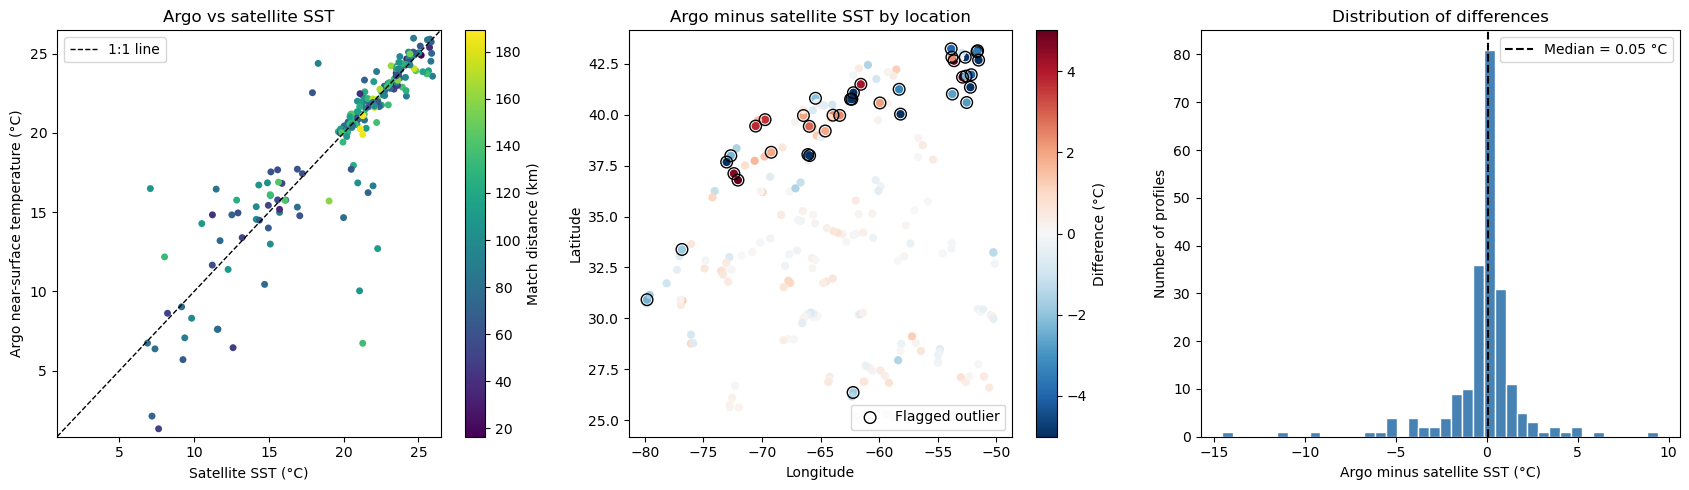

In [86]:
plot_summary(prof)

In [87]:
df_clean.head()

,index,N_PROF,N_LEVELS,CYCLE_NUMBER,DATA_MODE,DIRECTION,PLATFORM_NUMBER,PRES,PRES_ERROR,PSAL,PSAL_ERROR,TEMP,TEMP_ERROR,LATITUDE,LONGITUDE,TIME,matched_sst,match_dist_km,TEMP_MINUS_SST,MONTH_DAY
0,0,0,0,220,D,A,4903258,1.08,2.4,32.740398,0.01,6.448,0.002,42.82596,-52.65462,2023-01-01 02:16:37,12.6,48.544783,-6.152000,01-01
1,1,0,1,220,D,A,4903258,2.04,2.4,32.741100,0.01,6.454,0.002,42.82596,-52.65462,2023-01-01 02:16:37,12.6,48.544783,-6.146000,01-01
2,2,0,2,220,D,A,4903258,2.96,2.4,32.743099,0.01,6.470,0.002,42.82596,-52.65462,2023-01-01 02:16:37,12.6,48.544783,-6.130001,01-01
3,3,0,3,220,D,A,4903258,3.96,2.4,32.745201,0.01,6.458,0.002,42.82596,-52.65462,2023-01-01 02:16:37,12.6,48.544783,-6.142000,01-01
4,4,0,4,220,D,A,4903258,5.04,2.4,32.746700,0.01,6.459,0.002,42.82596,-52.65462,2023-01-01 02:16:37,12.6,48.544783,-6.141000,01-01


In [90]:
# print('data types, non-null counts, memory usage:\n')
# print(df_clean.info())

# # .describe() gives some summary statistics to explore the data
# print('\nsummary statistics for numeric columns:\n')
# print(df_clean.describe())

In [91]:
df_clean.to_csv('clean_data_gulfstream_jan_2023.csv', index=False)

prof.to_csv('clean_SURFACE_data_gulfstream_jan_2023.csv', index=False)